# Computational Comparison of Brute Force and Nearest Neighbor Algorithms for the Traveling Salesperson Problem

## Project Overview

This project investigates the performance of two algorithms for solving the **Asymmetric Traveling Salesperson Problem (ATSP)**: the Brute Force algorithm and the Nearest Neighbor heuristic.

The Brute Force algorithm is used to find the optimal solution, while the Nearest Neighbor algorithm provides a heuristic solution. Their performance is compared in terms of computational runtime and solution quality across randomly generated problem instances of different sizes.

The main objective is to evaluate the trade-off between solution quality and computational efficiency as the number of cities increases.

In [50]:
import sys
from pathlib import Path

# Add the project root directory to the Python module search path.
project_path = Path.cwd().parent
sys.path.append(str(project_path))

In [51]:
import pandas as pd
import time
from Algorithms import brute_force, nearest_neighbor, mtz_model
from functions import route_cost, generate_cost_matrix


### Reload Project Modules

Reload the project modules to apply any changes made to the Python source files during development.

In [52]:
import importlib

importlib.reload(brute_force)
importlib.reload(nearest_neighbor)
importlib.reload(route_cost)
importlib.reload(generate_cost_matrix)
importlib.reload(mtz_model)

<module 'Algorithms.mtz_model' from 'c:\\Users\\Ava\\Desktop\\Optimization\\Algorithms\\mtz_model.py'>

### Run Computational Experiments

This section evaluates the Brute Force and Nearest Neighbor algorithms on randomly generated ATSP instances of different sizes.

For each problem size, 50 cost matrices are generated using different random seeds. All three algorithms are executed for every possible starting city on the same cost matrix.

The execution time, tour cost, and optimality gap are recorded for each experiment. The generated cost matrices are also stored for reproducibility.

In [53]:
# Initialize lists to store experimental results and cost matrices.
results = []
cost_matrix = []

# Test problem sizes from 2 to 10 cities.
for N in range(2, 11):

    # Generate 50 different cost matrices for each problem size.
    for l in range(50):
        seed = 42 + l

        # Generate a reproducible random cost matrix.
        cities, cost = generate_cost_matrix.generate_cost_matrix(N, seed)

        # Store the problem size, seed, and generated cost matrix.
        cost_matrix.append({
            "N": N,
            "seed": seed,
            "cost_matrix": cost
        })

        # Evaluate all three algorithms using every city as the starting city.
        for j in range(N):
            start = j

            # Run the Brute Force algorithm and measure its execution time.
            start_time = time.perf_counter()
            bf_cost, bf_route = brute_force.brute_force(
                cities, cost, start, route_cost.route_cost
            )
            bf_duration = (time.perf_counter() - start_time) * 1000

            # Run the Nearest Neighbor algorithm and measure its execution time.
            start_time = time.perf_counter()
            nn_cost, nn_route = nearest_neighbor.nearest_neighbor(
                cities, cost, start, route_cost.route_cost
            )
            nn_duration = (time.perf_counter() - start_time) * 1000
            
            # Run the MTZ + ATSP Optimization Problem and measure its execution time.
            start_time = time.perf_counter()
            MTZ_cost, MTZ_route = mtz_model.mtz_model(
                cities, cost, start, route_cost.route_cost
            )
            MTZ_duration = (time.perf_counter() - start_time) * 1000
            if MTZ_cost is None:
                raise RuntimeError(
                    f"MTZ failed for N={N}, seed={seed}, stat={start}"
                )
            # Calculate the optimality gap relative to the optimal solution.
            nn_gap = (nn_cost - bf_cost) / bf_cost * 100
            
            # Calculate the optimality gap relative to the optimal solution.
            MTZ_gap = (MTZ_cost - bf_cost) / bf_cost * 100

            # Store the results of the current experiment.
            results.append({
                "N": N,
                "seed": seed,
                "start": start,
                "bf_cost": bf_cost,
                "bf_route": str(bf_route),
                "bf_duration_ms": bf_duration,
                "MTZ_cost": MTZ_cost,
                "MTZ_route": str(MTZ_route),
                "MTZ_duration_ms": MTZ_duration,
                "nn_cost": nn_cost,
                "nn_route": str(nn_route),
                "nn_duration_ms": nn_duration,
                "nn_gap_percent": nn_gap,
                "MTZ_gap_percent": MTZ_gap
            })

### Save Experimental Results

Convert the experimental results into a Pandas DataFrame and save them as a CSV file for further analysis.

In [54]:
# Convert the experimental results into a DataFrame.
df = pd.DataFrame(results)

# Create the Results directory if it does not already exist.
result_dir = project_path / "Results"
result_dir.mkdir(exist_ok=True)

# Save the experimental results as a CSV file.
df.to_csv(result_dir / "tsp_results.csv", index=False)

### Save Generated Cost Matrices

Convert the generated cost matrices into a DataFrame and save them as a CSV file. This allows the generated problem instances to be preserved for future reference and reproducibility.

In [55]:
# Convert the generated cost matrices into a DataFrame.
df_cost = pd.DataFrame(cost_matrix)

# Create the data directory if it does not already exist.
data_dir = project_path / "data"
data_dir.mkdir(exist_ok=True)

# Save the cost matrices as a CSV file.
df_cost.to_csv(data_dir / "cost_matrix.csv", index=False)

### Load and Inspect Results

This section loads the saved experimental results from the CSV file and performs initial checks to understand the dataset structure, verify the recorded observations, and identify any missing values before conducting further analysis.

In [56]:
# Load the experimental results from the CSV file.
df = pd.read_csv(result_dir / "tsp_results.csv")

# Display the first five rows of the dataset.
display(df.head())

# Display the dataset dimensions (rows and columns).
print("Dataset shape:", df.shape)

# Display column names and data types.
df.info()

# Check for missing values in each column.
display(df.isnull().sum())

,N,seed,start,bf_cost,bf_route,bf_duration_ms,MTZ_cost,MTZ_route,MTZ_duration_ms,nn_cost,nn_route,nn_duration_ms,nn_gap_percent,MTZ_gap_percent
0,2,42,0,43,"(0, 1)",0.0307,43,"[0, 1, 0]",117.1711,43,"[0, 1]",0.0103,0.0,0.0
1,2,42,1,43,"(1, 0)",0.0215,43,"[1, 0, 1]",107.3580,43,"[1, 0]",0.0091,0.0,0.0
2,2,43,0,30,"(0, 1)",0.0172,30,"[0, 1, 0]",138.1254,30,"[0, 1]",0.0082,0.0,0.0
3,2,43,1,30,"(1, 0)",0.0267,30,"[1, 0, 1]",46.6283,30,"[1, 0]",0.0109,0.0,0.0
4,2,44,0,49,"(0, 1)",0.0185,49,"[0, 1, 0]",37.6379,49,"[0, 1]",0.0100,0.0,0.0


Dataset shape: (2700, 14)
<class 'pandas.DataFrame'>
RangeIndex: 2700 entries, 0 to 2699
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   N                2700 non-null   int64  
 1   seed             2700 non-null   int64  
 2   start            2700 non-null   int64  
 3   bf_cost          2700 non-null   int64  
 4   bf_route         2700 non-null   str    
 5   bf_duration_ms   2700 non-null   float64
 6   MTZ_cost         2700 non-null   int64  
 7   MTZ_route        2700 non-null   str    
 8   MTZ_duration_ms  2700 non-null   float64
 9   nn_cost          2700 non-null   int64  
 10  nn_route         2700 non-null   str    
 11  nn_duration_ms   2700 non-null   float64
 12  nn_gap_percent   2700 non-null   float64
 13  MTZ_gap_percent  2700 non-null   float64
dtypes: float64(5), int64(6), str(3)
memory usage: 295.4 KB


N                  0
seed               0
start              0
bf_cost            0
bf_route           0
bf_duration_ms     0
MTZ_cost           0
MTZ_route          0
MTZ_duration_ms    0
nn_cost            0
nn_route           0
nn_duration_ms     0
nn_gap_percent     0
MTZ_gap_percent    0
dtype: int64

In [57]:
# Calculate median runtime for each algorithm by problem size.
runtime_medians = df.groupby("N")[
    ["bf_duration_ms", "nn_duration_ms", "MTZ_duration_ms"]
].median()

# Calculate how many times slower Brute Force is than Nearest Neighbor.
runtime_medians["nn_runtime_ratio"] = (
    runtime_medians["bf_duration_ms"]
    / runtime_medians["nn_duration_ms"]
)

# Calculate how many times slower Brute Force is than MTZ.
runtime_medians["MTZ_runtime_ratio"] = (
    runtime_medians["bf_duration_ms"]
    / runtime_medians["MTZ_duration_ms"]
)

display(runtime_medians.round(2))

,bf_duration_ms,nn_duration_ms,MTZ_duration_ms,nn_runtime_ratio,MTZ_runtime_ratio
N,,,,,
2,0.01,0.01,23.53,2.25,0.00
3,0.01,0.01,23.18,2.04,0.00
4,0.02,0.01,27.70,2.71,0.00
5,0.07,0.01,37.79,6.26,0.00
6,0.33,0.01,48.51,23.85,0.01
7,2.01,0.02,73.11,116.09,0.03
8,15.66,0.02,66.01,680.91,0.24
9,141.62,0.04,143.69,3961.35,0.99
10,1184.46,0.04,142.30,31376.41,8.32


### Optimality Gap Analysis

This section evaluates the solution quality of the Nearest Neighbor algorithm compared with the optimal solutions obtained by Brute Force.

The optimality gap is grouped by problem size (number of cities). Mean, median, minimum, maximum, and standard deviation are calculated to examine the average performance and variability of the heuristic algorithm across different problem instances and starting cities.

In [58]:
# Calculate descriptive statistics of the optimality gap for each problem size.
gap_analysis = df.groupby("N")[["nn_gap_percent","MTZ_gap_percent"]].agg(
    ["mean", "median", "min", "max", "std"]
)

# Display the analysis results.
display(gap_analysis)

nn_gap_percent                                       MTZ_gap_percent  \
             mean     median  min        max        std            mean   
N                                                                         
2        0.000000   0.000000  0.0   0.000000   0.000000             0.0   
3        6.734174   0.000000  0.0  69.642857  14.135628             0.0   
4       10.042580   0.000000  0.0  89.090909  15.521183             0.0   
5       13.049234   9.900990  0.0  70.833333  13.534515             0.0   
6       14.937842  11.814556  0.0  68.316832  14.685850             0.0   
7       16.351778  14.775828  0.0  61.224490  12.998979             0.0   
8       17.205379  16.860465  0.0  80.000000  12.089229             0.0   
9       18.351230  17.647059  0.0  49.606299  11.783855             0.0   
10      18.941292  18.477345  0.0  60.305344  11.456906             0.0   

                          
   median  min  max  std  
N                         
2     0.0  0.0  0.0  0.0  
3     0.0  0.0  0.0  0.0  
4     0.0  0.0  0.0  0.0  
5     0.0  0.0  0.0  0.0  
6     0.0  0.0  0.0  0.0  
7     0.0  0.0  0.0  0.0  
8     0.0  0.0  0.0  0.0  
9     0.0  0.0  0.0  0.0  
10    0.0  0.0  0.0  0.0

### Starting City Impact Analysis

This section investigates how the choice of starting city affects the solution quality of the Nearest Neighbor algorithm.

For each problem size, the mean optimality gap is calculated separately for each starting city across all generated cost matrices. Bar charts are used to compare the average solution quality associated with different starting cities.

<Figure size 700x400 with 0 Axes>

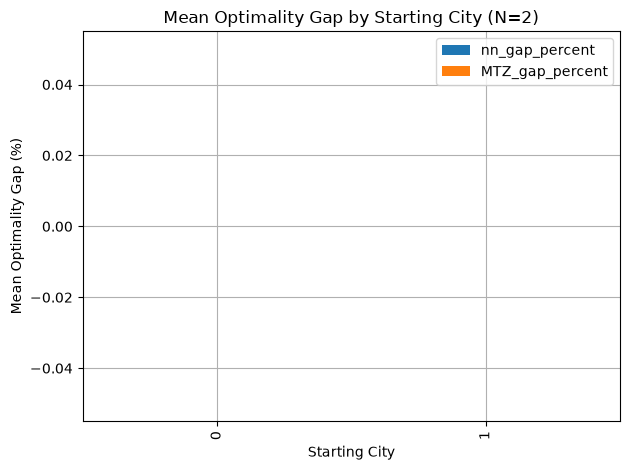

<Figure size 700x400 with 0 Axes>

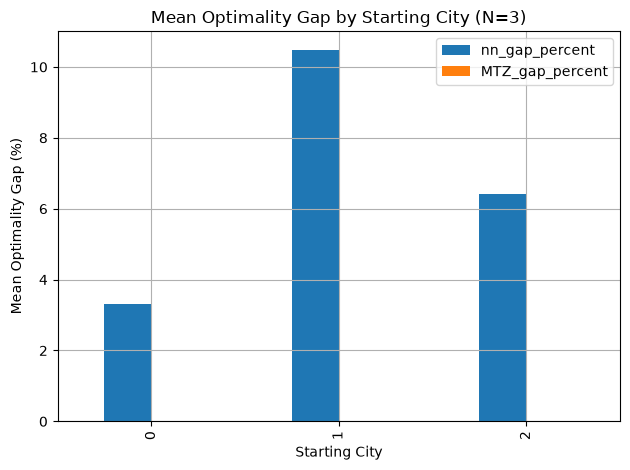

<Figure size 700x400 with 0 Axes>

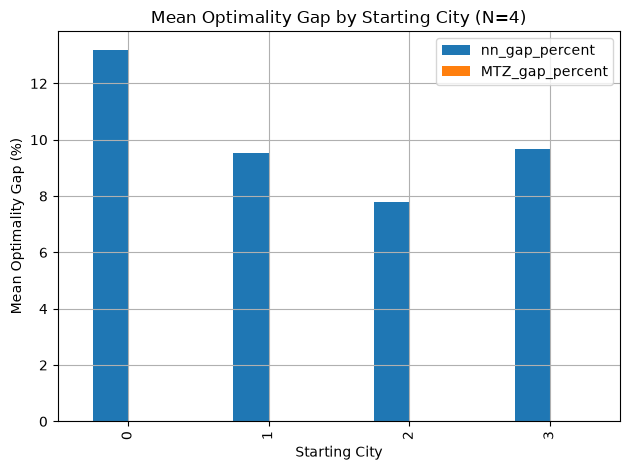

<Figure size 700x400 with 0 Axes>

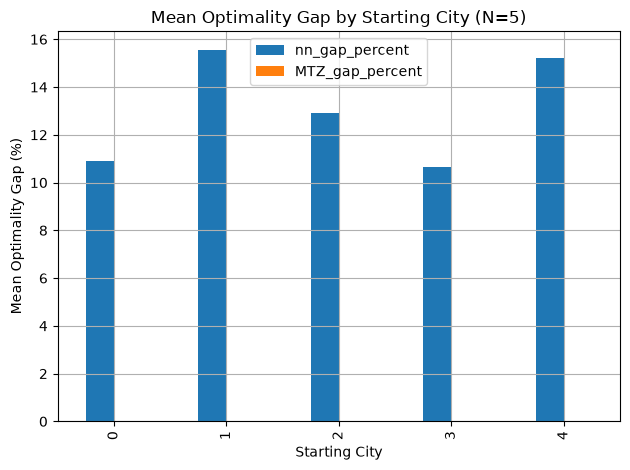

<Figure size 700x400 with 0 Axes>

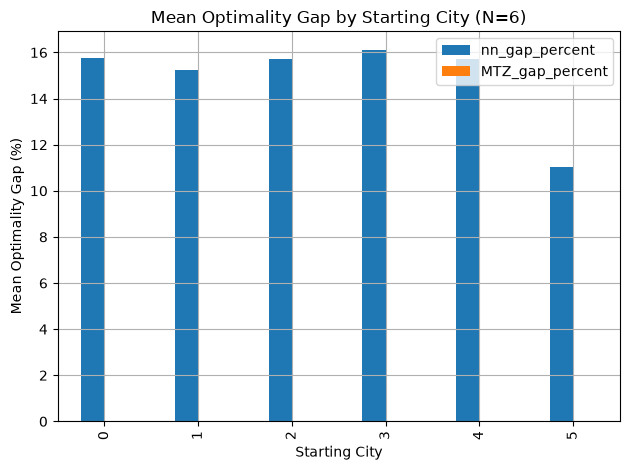

<Figure size 700x400 with 0 Axes>

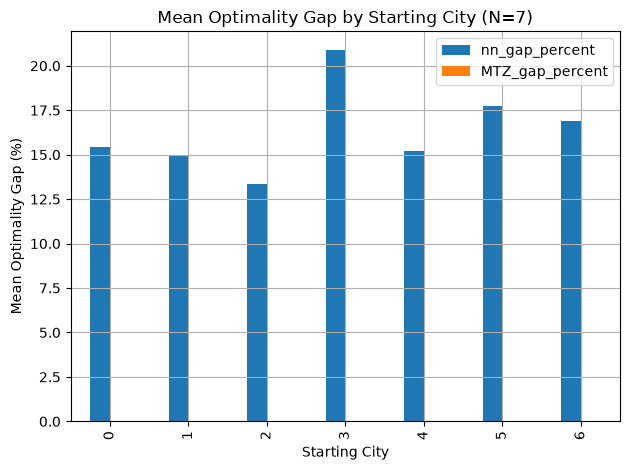

<Figure size 700x400 with 0 Axes>

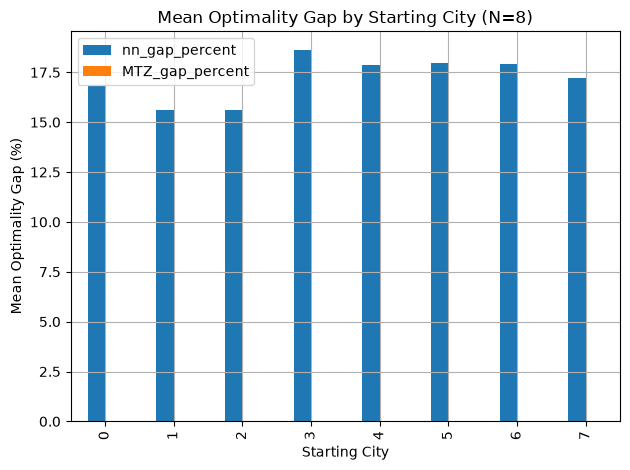

<Figure size 700x400 with 0 Axes>

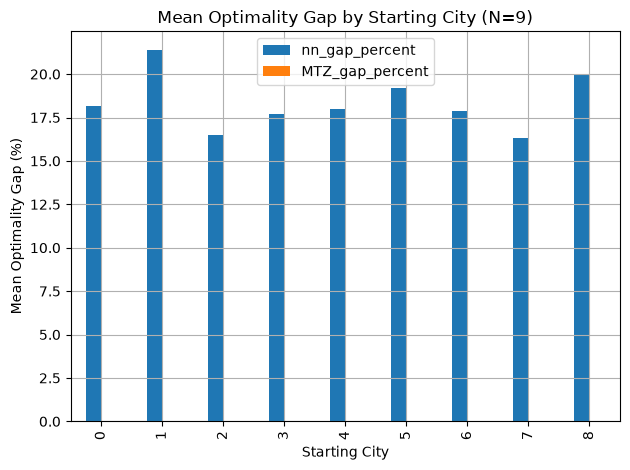

<Figure size 700x400 with 0 Axes>

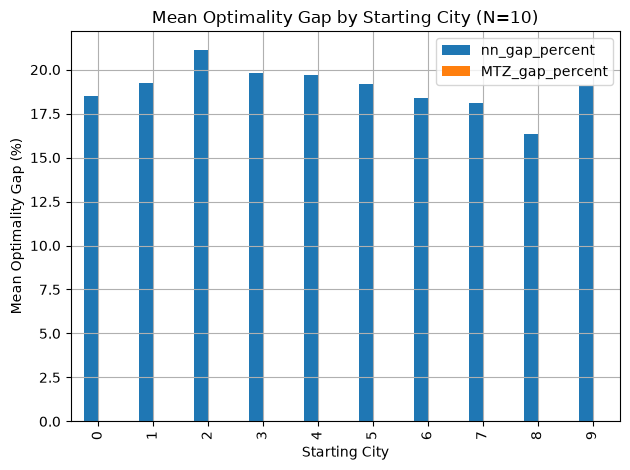

In [60]:
import matplotlib.pyplot as plt

# Analyze the effect of the starting city for each problem size.
for N in sorted(df["N"].unique()):

    # Select the observations corresponding to the current problem size.
    subset = df[df["N"] == N]

    # Calculate the mean optimality gap for each starting city.
    start_analysis = subset.groupby("start")[["nn_gap_percent","MTZ_gap_percent"]].mean()

    # Create a bar chart to compare starting cities.
    plt.figure(figsize=(7, 4))
    start_analysis.plot(
        kind="bar",
        xlabel="Starting City",
        ylabel="Mean Optimality Gap (%)",
        title=f"Mean Optimality Gap by Starting City (N={N})",
        grid=True
    )

    # Adjust the layout and display the chart.
    plt.tight_layout()
    plt.show()

### Starting City Comparison Table

This section summarizes the mean optimality gap for each problem size and starting city in a pivot table.

The table provides a compact overview of how the starting city affects the solution quality of the Nearest Neighbor algorithm across different problem sizes.

In [61]:
# Calculate the mean optimality gap for each problem size and starting city.
gap_table = df.pivot_table(
    index="N",
    columns="start",
    values="nn_gap_percent",
    aggfunc="mean"
)

# Display the table with values rounded to two decimal places.
display(gap_table.round(2))

start,0,1,2,3,4,5,6,7,8,9
N,,,,,,,,,,
2,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3.30,10.48,6.42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,13.19,9.53,7.79,9.66,NaN,NaN,NaN,NaN,NaN,NaN
5,10.91,15.55,12.93,10.65,15.20,NaN,NaN,NaN,NaN,NaN
6,15.76,15.26,15.73,16.11,15.73,11.03,NaN,NaN,NaN,NaN
7,15.44,14.91,13.36,20.89,15.23,17.75,16.88,NaN,NaN,NaN
8,16.82,15.59,15.63,18.62,17.88,17.96,17.94,17.20,NaN,NaN
9,18.17,21.39,16.50,17.73,17.98,19.23,17.86,16.30,20.00,NaN
10,18.51,19.26,21.12,19.78,19.69,19.21,18.39,18.08,16.32,19.06


### Best and Worst Starting City Analysis

This section identifies the best and worst starting cities for each problem size based on their mean optimality gaps.

The difference between the best and worst mean gaps is also calculated to evaluate how strongly the choice of starting city affects the solution quality of the Nearest Neighbor algorithm.

In [62]:
# Initialize a list to store the summary for each problem size.
summary_rows = []

# Analyze the starting city performance for each problem size.
for N, group in gap_table.iterrows():

    # Exclude missing values for starting cities that do not exist.
    valid = group.dropna()

    # Identify the starting city with the lowest mean optimality gap.
    best_start = valid.idxmin()

    # Identify the starting city with the highest mean optimality gap.
    worst_start = valid.idxmax()

    # Store the best, worst, and difference in mean optimality gaps.
    summary_rows.append({
        "N": N,
        "Best start": best_start,
        "Best mean gap (%)": valid.min(),
        "Worst start": worst_start,
        "Worst mean gap (%)": valid.max(),
        "Difference (percentage points)": valid.max() - valid.min()
    })

# Convert the summary into a DataFrame and use N as the index.
starting_city_summary = pd.DataFrame(summary_rows).set_index("N")

# Display the summary rounded to two decimal places.
display(starting_city_summary.round(2))

,Best start,Best mean gap (%),Worst start,Worst mean gap (%),Difference (percentage points)
N,,,,,
2,0,0.00,0,0.00,0.00
3,0,3.30,1,10.48,7.18
4,2,7.79,0,13.19,5.40
5,3,10.65,1,15.55,4.90
6,5,11.03,3,16.11,5.08
7,2,13.36,3,20.89,7.53
8,1,15.59,3,18.62,3.03
9,7,16.30,1,21.39,5.10
10,8,16.32,2,21.12,4.81


### Save Starting City Analysis Results

This section exports the starting city analysis tables as CSV files. These files preserve the detailed mean optimality gaps and the summary of the best and worst starting cities for each problem size.

In [63]:
# Save the starting city comparison table.
gap_table.round(2).to_csv(
    data_dir / "starting_city_gap_table.csv"
)

# Save the best and worst starting city summary.
starting_city_summary.round(2).to_csv(
    data_dir / "starting_city_summary.csv"
)

### Runtime Analysis

This section compares the computational runtime of the Brute Force and Nearest Neighbor algorithms across different problem sizes.

For each problem size, the mean, median, and standard deviation of the execution times are calculated. These statistics help evaluate the computational efficiency and runtime variability of all three algorithms.

In [64]:
# Calculate runtime statistics for all three algorithms for each problem size.
time_analysis = df.groupby("N")[
    ["bf_duration_ms", "nn_duration_ms", "MTZ_duration_ms"]
].agg(["mean", "median", "std"])

# Display the runtime analysis results.
display(time_analysis)

bf_duration_ms                         nn_duration_ms                     \
             mean      median         std           mean   median       std   
N                                                                             
2        0.014533     0.01170    0.008544       0.005997  0.00520  0.001851   
3        0.016097     0.01370    0.009784       0.007522  0.00670  0.003002   
4        0.026128     0.02320    0.016312       0.009652  0.00855  0.003867   
5        0.096058     0.06700    0.200767       0.012213  0.01070  0.005133   
6        0.383350     0.33395    0.180520       0.019018  0.01400  0.030909   
7        2.133165     2.00830    0.753252       0.025163  0.01730  0.061670   
8       15.273798    15.66100    3.100097       0.026605  0.02300  0.018048   
9      143.960511   141.61840   30.680373       0.041022  0.03575  0.017582   
10    1290.271802  1184.45965  172.944609       0.043566  0.03775  0.018856   

   MTZ_duration_ms                         
              mean     median         std  
N                                          
2        33.772164   23.53110   32.032859  
3        23.800416   23.18060    2.183819  
4        34.853705   27.70310   40.535446  
5        46.791753   37.78955   25.132346  
6        56.319872   48.51455   27.451558  
7        88.851848   73.10700   54.268289  
8        92.019504   66.01100   56.819920  
9       166.526637  143.69180   93.911021  
10      169.530329  142.30210  106.366969

### Runtime Comparison Visualization

This section visualizes the average execution time of the Brute Force and Nearest Neighbor algorithms for different problem sizes.

A logarithmic scale is used on the vertical axis to make the runtime differences between the two algorithms easier to observe, particularly when their execution times differ by several orders of magnitude.

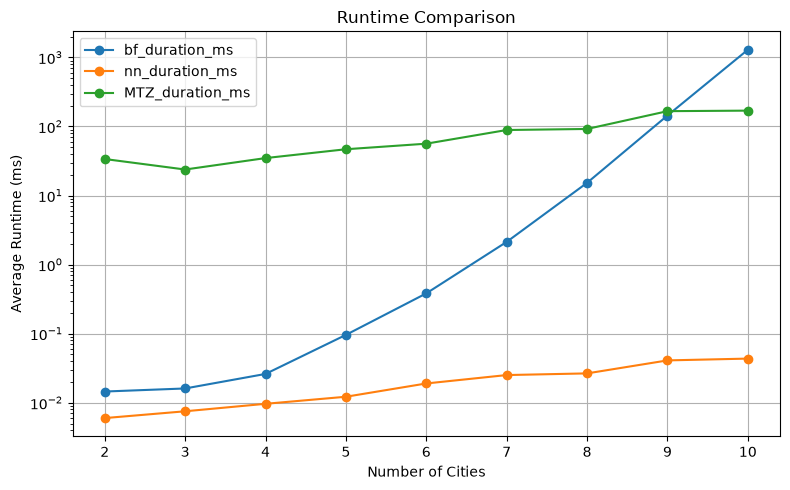

In [65]:
import matplotlib.pyplot as plt

# Calculate the mean execution time of all three algorithms for each problem size.
time_means = df.groupby("N")[
    ["bf_duration_ms", "nn_duration_ms", "MTZ_duration_ms"]
].mean()

# Plot the average runtimes of all three algorithms.
time_means.plot(marker="o", figsize=(8, 5))

# Use a logarithmic scale to display large differences in runtime.
plt.yscale("log")

# Add axis labels and chart title.
plt.xlabel("Number of Cities")
plt.ylabel("Average Runtime (ms)")
plt.title("Runtime Comparison")

# Display grid lines and the plot.
plt.grid(True)
plt.tight_layout()
plt.show()

### Optimality Gap Visualization

This section visualizes the average optimality gap of the Nearest Neighbor algorithm across different problem sizes.

The plot illustrates how the solution quality of the heuristic algorithm changes as the number of cities increases.

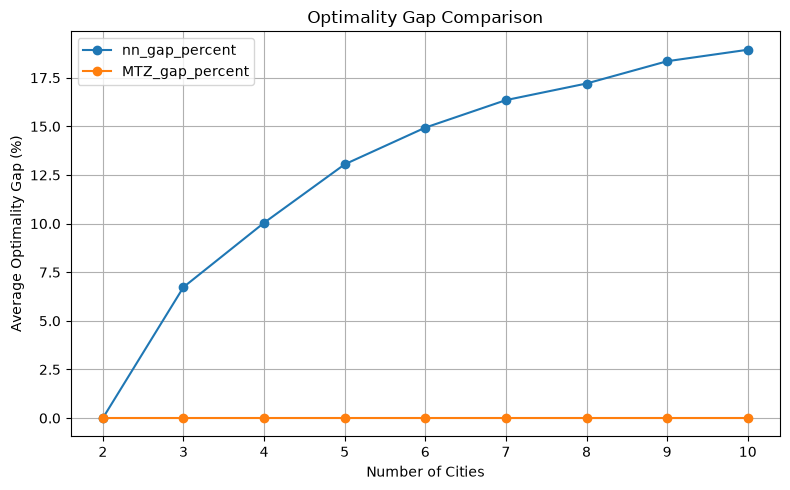

In [66]:
# Calculate the mean optimality gap for each problem size.
gap_means = df.groupby("N")[
    ["nn_gap_percent", "MTZ_gap_percent"]
    ].mean()

# Plot the average optimality gap.
gap_means.plot(marker="o", figsize=(8, 5))

# Add axis labels and chart title.
plt.xlabel("Number of Cities")
plt.ylabel("Average Optimality Gap (%)")
plt.title("Optimality Gap Comparison")

# Display grid lines and the plot.
plt.grid(True)
plt.tight_layout()
plt.show()

### Solution Cost Comparison

This section compares the average tour costs obtained by the Brute Force and Nearest Neighbor algorithms across different problem sizes.

Since Brute Force provides the optimal solution, its average tour cost serves as a benchmark for evaluating the solution quality of the Nearest Neighbor heuristic.

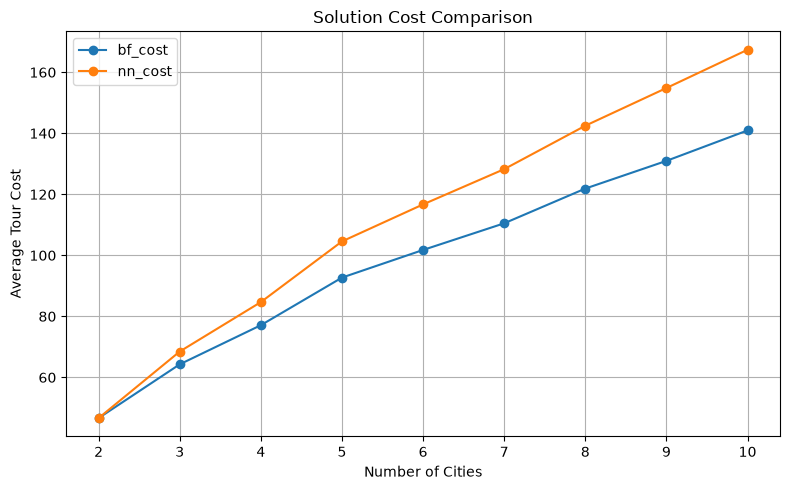

In [68]:
# Calculate the mean tour cost of all three algorithms for each problem size.
cost_means = df.groupby("N")[
    ["bf_cost", "nn_cost"]
].mean()

# Plot the average tour costs of all three algorithms.
cost_means.plot(marker="o", figsize=(8, 5))

# Add axis labels and chart title.
plt.xlabel("Number of Cities")
plt.ylabel("Average Tour Cost")
plt.title("Solution Cost Comparison")

# Display grid lines and the plot.
plt.grid(True)
plt.tight_layout()
plt.show()

## Conclusion

This notebook presents a computational comparison of the Brute Force and Nearest Neighbor algorithms for the Asymmetric Traveling Salesperson Problem (ATSP).

The experiments were conducted for problem sizes ranging from 2 to 10 cities, using 50 randomly generated cost matrices for each size and evaluating every possible starting city. The performance of all three algorithms was compared in terms of solution quality, computational runtime, and optimality gap.

The results show that Brute Force consistently finds optimal solutions for the tested instances, making it a reliable benchmark for evaluating the Nearest Neighbor heuristic. However, its computational runtime increases rapidly as the problem size grows. In contrast, Nearest Neighbor is considerably faster, but does not always produce optimal solutions. Its solution quality also varies depending on the selected starting city.

For instances with 10 cities, the median runtime of Brute Force was approximately 1,250.86 ms, compared with 0.0370 ms for Nearest Neighbor. This corresponds to a runtime ratio of approximately 33,807, illustrating the substantial computational advantage of the heuristic for the tested instances.

The starting city analysis further indicates that the choice of initial city affects the solution quality of Nearest Neighbor, although no single starting city consistently provides the best results across all problem sizes.

Overall, the findings demonstrate the trade-off between optimality and computational efficiency in exact and heuristic optimization methods. Brute Force is suitable for small instances where finding the optimal solution is essential, whereas Nearest Neighbor offers a much faster alternative when computational efficiency is important. Further research could extend this comparison to larger problem instances and additional optimization algorithms.